# Lorenz–96 conditional ensemble comparison

Frozen exploratory study: three objectives, three paired training seeds, three forecast horizons.
All figures require the audited production outputs. Shading shows one standard deviation
across training seeds, not a confidence interval. Paired bootstrap intervals are saved separately.
Larger coverage is not automatically better: the nominal target is 0.90 and interval width matters.

Forecast horizons are evaluated as conditional marginals. Sampling independently at each lead
does not define coherent joint trajectories across lead times. This is a controlled benchmark,
not an operational weather model. Equal-time comparisons use saved checkpoints rounded down
to the common budget; inspect selected steps and actual training times before interpreting them.


In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'font.size': 14, 'axes.labelsize': 16, 'lines.linewidth': 2,
    'legend.frameon': False, 'xtick.direction': 'in', 'ytick.direction': 'in',
    'axes.grid': True,
})
# Mathtext keeps this portable without a system LaTeX installation.
COLORS = {'riesz': 'steelblue', 'flow_matching': 'forestgreen', 'riesz_no_repulsion': 'darkorange'}
LABELS = {'riesz': 'MMD/Riesz', 'flow_matching': 'Flow matching', 'riesz_no_repulsion': 'No repulsion'}


In [2]:
candidates = [Path.cwd(), *Path.cwd().parents]
repo = next(p for p in candidates if (p / 'experiments/lorenz96_ensemble_20261030/config.json').exists())
result_dir = repo / 'results/lorenz96/ensemble_20261030/production'
figure_dir = result_dir / 'figures'
assert json.loads((result_dir / 'ready.json').read_text())['complete']
assert json.loads((result_dir / 'audit.json').read_text())['passed']
config = json.loads((result_dir / 'config.json').read_text())
summary = json.loads((result_dir / 'summary.json').read_text())
figure_dir.mkdir(parents=True, exist_ok=True)
leads = np.array(config['lead_times'])
methods = config['methods']
seeds = config['seeds']
values = {}
for tag in ['equal_updates', 'equal_time', 'refinement']:
    values[tag] = {}
    for method in methods:
        runs = []
        for seed in seeds:
            with np.load(result_dir / 'runs' / f'{method}_seed{seed}' / f'{tag}.npz') as data:
                assert data['ensemble'].shape == (config['test_contexts'], len(leads), config['ensemble_size'], config['dimension'])
                runs.append({k: data[k] for k in data.files if k != 'ensemble'})
        values[tag][method] = {k: np.stack([r[k].mean(axis=0) for r in runs]) for k in runs[0]}
with np.load(result_dir / 'baselines.npz') as data:
    baselines = {k: data[k].mean(axis=0) for k in data.files}


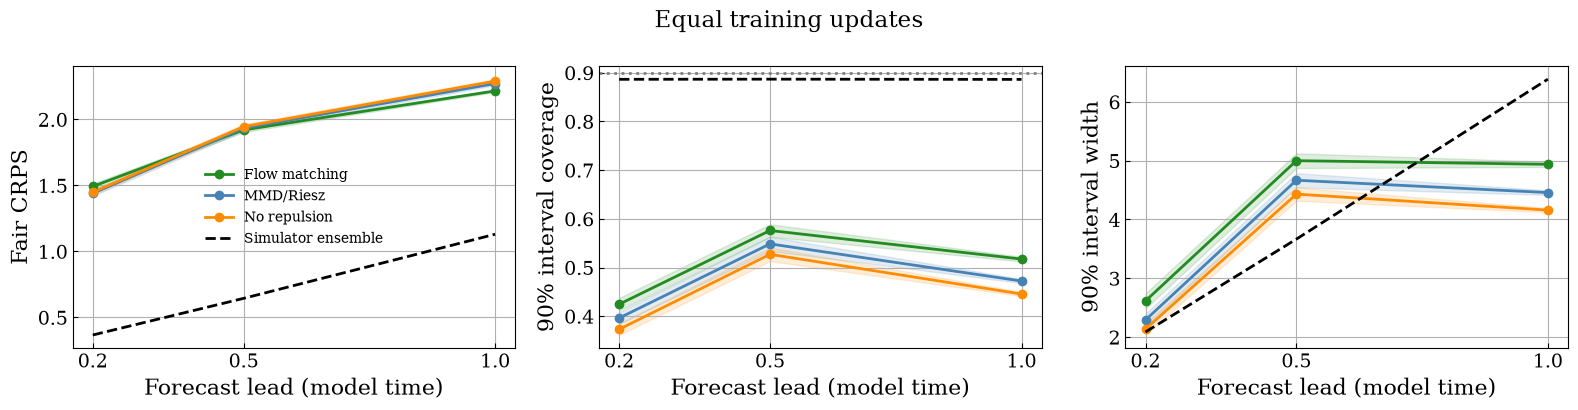

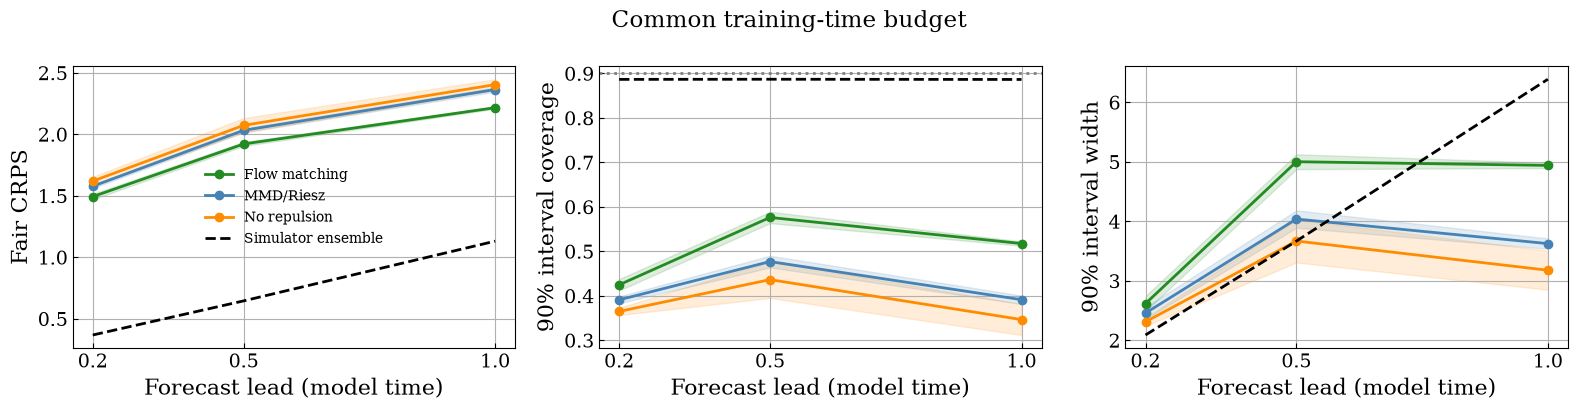

In [3]:
for tag, title in [('equal_updates', 'Equal training updates'), ('equal_time', 'Common training-time budget')]:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for ax, metric, label in zip(axes, ['crps', 'coverage90', 'width90'], ['Fair CRPS', '90% interval coverage', '90% interval width']):
        for method in methods:
            v = values[tag][method][metric]
            mean, std = v.mean(axis=0), v.std(axis=0, ddof=1)
            ax.plot(leads, mean, marker='o', color=COLORS[method], label=LABELS[method])
            ax.fill_between(leads, mean-std, mean+std, color=COLORS[method], alpha=.15)
        ax.plot(leads, baselines['simulator_ensemble__'+metric], '--', color='black', label='Simulator ensemble')
        if metric == 'coverage90':
            ax.axhline(.9, color='grey', linestyle=':', label='Nominal coverage')
        ax.set(xlabel='Forecast lead (model time)', ylabel=label, xticks=leads)
    axes[0].legend(fontsize=10)
    fig.suptitle(title)
    plt.tight_layout()
    fig.savefig(figure_dir / f'{tag}_calibration.pdf', bbox_inches='tight')
    fig.savefig(figure_dir / f'{tag}_calibration.png', dpi=150, bbox_inches='tight')
    plt.show()


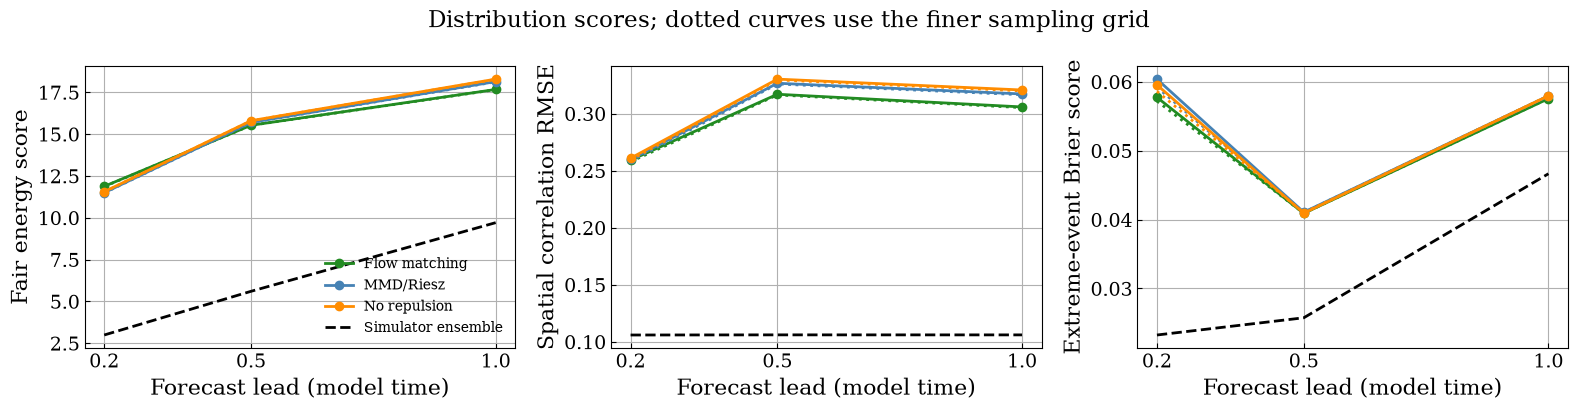

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, metric, label in zip(axes, ['energy_score', 'correlation_rmse', 'brier_extreme'], ['Fair energy score', 'Spatial correlation RMSE', 'Extreme-event Brier score']):
    for method in methods:
        v = values['equal_updates'][method][metric]
        ax.plot(leads, v.mean(axis=0), marker='o', color=COLORS[method], label=LABELS[method])
        ax.plot(leads, values['refinement'][method][metric].mean(axis=0), ':', color=COLORS[method])
    ax.plot(leads, baselines['simulator_ensemble__'+metric], '--', color='black', label='Simulator ensemble')
    ax.set(xlabel='Forecast lead (model time)', ylabel=label, xticks=leads)
axes[0].legend(fontsize=10)
fig.suptitle('Distribution scores; dotted curves use the finer sampling grid')
plt.tight_layout()
fig.savefig(figure_dir / 'joint_scores_refinement.pdf', bbox_inches='tight')
fig.savefig(figure_dir / 'joint_scores_refinement.png', dpi=150, bbox_inches='tight')
plt.show()


In [5]:
# Signed effects: negative differences favour the method for proper scores.
for row in summary['comparisons']:
    if row['comparison'] == 'equal_updates' and row['metric'] in ['crps', 'energy_score']:
        print(f"{row['method']:20s} lead={row['lead']:.1f} {row['metric']:12s} "
              f"difference={row['difference']:+.4f}, 95% CI={row['ci95']}")
print('Limitations:')
for note in summary['limitations']:
    print('-', note)


riesz                lead=0.2 crps         difference=-0.0523, 95% CI=[-0.05901622270116833, -0.04577920680078619]
riesz                lead=0.5 crps         difference=+0.0133, 95% CI=[0.006598595684642912, 0.019672864575453617]
riesz                lead=1.0 crps         difference=+0.0559, 95% CI=[0.04874442058847255, 0.06385213118695501]
riesz                lead=0.2 energy_score difference=-0.3811, 95% CI=[-0.4349445458286057, -0.33296889040141925]
riesz                lead=0.5 energy_score difference=+0.1713, 95% CI=[0.11975760375074614, 0.22150673339640967]
riesz                lead=1.0 energy_score difference=+0.4704, 95% CI=[0.4194157797606956, 0.5296473372778125]
riesz_no_repulsion   lead=0.2 crps         difference=-0.0443, 95% CI=[-0.051154045038223586, -0.03747201026135084]
riesz_no_repulsion   lead=0.5 crps         difference=+0.0249, 95% CI=[0.01718612897856113, 0.0317681190665249]
riesz_no_repulsion   lead=1.0 crps         difference=+0.0747, 95% CI=[0.06645011737578509,